# 02 – Test-set shift study

**Goal.** Measure *how* the test images differ from the clean training images, so that the **shifted validation** (notebook `03_validation_setup`) can reproduce the same alterations, in the **same proportions** and with the **same strength**.

We only use **unlabelled statistics** of the test images (the 14,736 images contain both the public and the private part of the leaderboard). No test label is used anywhere.

| # | question |
|---|---|
| 1 | Colour: how many test images have altered colours, and **what is the mechanism**? |
| 2 | Blur: how many test images are blurred, and **how strongly**? |
| 3 | Other differences (sky grain, brighter sky, blank images) |
| 4 | Proposal for the shifted validation |

The reference for "normal" images is always the **clean training set** (2,995 images, `splits/clean_train.csv`). The results are cross-checked with Davide's independent audit (`eda/01_audit_davide.py`).

Requires `outputs/meta.csv` (from `00_eda`) and `splits/clean_train.csv` (from `01_clean_dataset`).

## 0. Setup

In [1]:
import colorsys

import numpy as np
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import common as C

plt.rcParams["figure.dpi"] = 80
meta = pd.read_csv(C.OUT / "meta.csv")
clean = pd.read_csv(C.SPLITS / "clean_train.csv")
keep_ids = set(clean[clean.keep].id)
train = meta[meta.id.isin(keep_ids)].copy()            # clean training set
test = meta[meta.split == "test"].copy()
print(f"clean train: {len(train)}  |  test: {len(test)}")


def show(ids, titles=None, ncols=8, size=1.8, suptitle=None, transform=None):
    # grid of images; 'transform' optionally modifies each image before showing it
    ids = list(ids)
    nrows = int(np.ceil(len(ids) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.12))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for k, (ax, i) in enumerate(zip(np.atleast_1d(axes).ravel(), ids)):
        img = C.load_image(i)
        ax.imshow(transform(img) if transform else img)
        ax.set_title(titles[k] if titles else i.split("_")[1], fontsize=7)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()

clean train: 2995  |  test: 14736


## 1. Colour

### 1a. Measuring the colour of the galaxy
The mean colour of the whole image is dominated by the dark sky and hides the colour of the galaxy. We measure instead the **core colour**: the mean R, G, B of the 10% brightest pixels in the central 96×96 square, where the galaxy is.

From it we compute the **chromaticity** (share of each channel: R/(R+G+B), G/(R+G+B), B/(R+G+B)), which depends on the colour and not on the brightness. A neutral grey/white core has 1/3, 1/3, 1/3. The computation takes a minute and is cached.

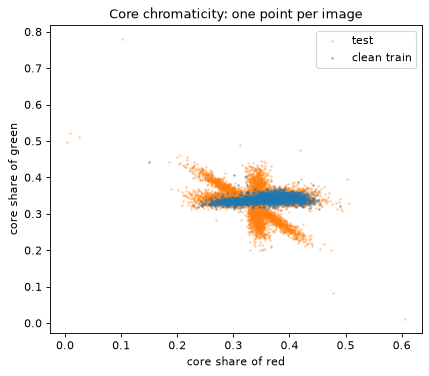

In [2]:
def core_rgb(img_id):
    a = np.asarray(C.load_image(img_id), np.float32)[80:176, 80:176].reshape(-1, 3)
    L = a.sum(1)
    return a[L >= np.quantile(L, 0.9)].mean(0)          # mean R, G, B of the brightest 10%

cache = C.OUT / "core_rgb.csv"
if cache.exists():
    core = pd.read_csv(cache)
else:
    core = pd.DataFrame([dict(zip(["id", "core_r", "core_g", "core_b"], [i, *core_rgb(i)])) for i in tqdm(meta.id)])
    core.to_csv(cache, index=False)

def add_chroma(df):
    s = df.core_r + df.core_g + df.core_b + 1e-6
    return df.assign(cr=df.core_r / s, cg=df.core_g / s, cb=df.core_b / s)

train = add_chroma(train.merge(core, on="id"))
test = add_chroma(test.merge(core, on="id"))

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(test.cr, test.cg, s=2, alpha=.25, color="tab:orange", label="test")
ax.scatter(train.cr, train.cg, s=2, alpha=.4, color="tab:blue", label="clean train")
ax.set_xlabel("core share of red"); ax.set_ylabel("core share of green"); ax.legend()
ax.set_title("Core chromaticity: one point per image"); plt.show()

**How to read it.** The clean training set forms a narrow band (natural galaxy colours, from yellow ellipticals to blue spirals). The test has the same band plus **two diagonal arms**: images whose core has too little green (pink/purple) or too much green.

### 1b. How many test images are tinted
We use Davide's rule: an image is **tinted** if its core green share falls outside the **1st–99th percentile** of the clean training set. By construction only 2% of the clean training set is flagged (its natural extremes), so this is the "false alarm" rate.

- green share **too low** → the core looks **purple / pink**;
- green share **too high** → the core looks **green**.

In [3]:
lo, hi = np.quantile(train.cg, [0.01, 0.99])
def tint(df):
    return np.where(df.cg < lo, "purple", np.where(df.cg > hi, "green", ""))
train["tint"], test["tint"] = tint(train), tint(test)

summary = pd.DataFrame({
    "clean train": pd.Series(train.tint).value_counts(normalize=True),
    "test": pd.Series(test.tint).value_counts(normalize=True),
}).mul(100).round(1).rename(index={"": "natural"})
print(f"green-share bounds (1-99% of clean train): {lo:.4f} - {hi:.4f}")
summary

green-share bounds (1-99% of clean train): 0.3208 - 0.3628


,clean train,test
tint,,
natural,98.0,78.2
green,1.0,9.1
purple,1.0,12.7


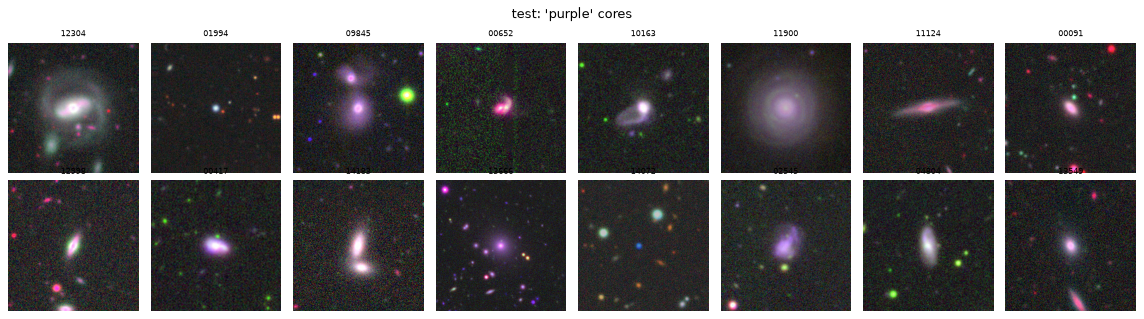

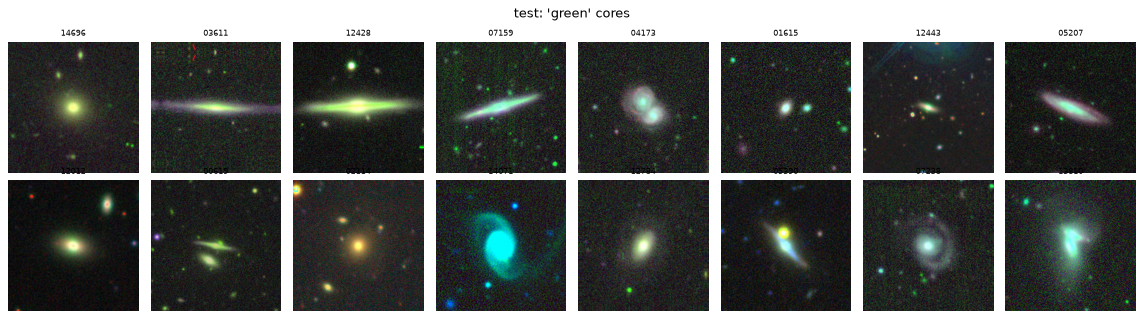

In [4]:
show(test[test.tint == "purple"].sample(16, random_state=0).id, suptitle="test: 'purple' cores")
show(test[test.tint == "green"].sample(16, random_state=0).id, suptitle="test: 'green' cores")

**Reading.** About **22–23%** of the test is tinted, against 2% of the clean training set (the false alarms). Subtracting them, roughly **one test image in five** has a clearly altered colour. The stars around the galaxy are also off-colour (green, pink), so the alteration affects **the whole image**.

*Cross-check:* Davide's audit finds 3,320 tinted test images (22.5%): 1,997 purple and 1,393 green.

### 1c. The mechanism: a rotation of the hue
A natural first guess is that the R, G, B channels were **swapped**. We test it, and the alternative that the **hue** (the angle on the colour wheel) was **rotated**: for every tinted test image we try to undo the alteration on the core colour and check whether the result falls inside the cloud of clean training colours (Mahalanobis distance below the 99th percentile of the clean training set).

- **channel swaps:** the 5 non-trivial permutations of R, G, B;
- **hue rotations:** rotate the hue by every angle from −180° to 170° in steps of 10° (saturation and brightness unchanged).

In [5]:
X_tr = train[["cr", "cg"]].to_numpy()
mu, cov_inv = X_tr.mean(0), np.linalg.inv(np.cov(X_tr.T))
def dist_rgb(rgb):
    x = rgb / (rgb.sum(1, keepdims=True) + 1e-6)
    d = x[:, :2] - mu
    return np.sqrt(np.einsum("ij,jk,ik->i", d, cov_inv, d))
thr = np.quantile(dist_rgb(train[["core_r", "core_g", "core_b"]].to_numpy()), 0.99)

def rotate_hue_rgb(rgb, deg):
    # rotate the hue of an array of RGB colours (0-255) by deg degrees
    out = [colorsys.hsv_to_rgb((h + deg / 360) % 1, s, v)
           for h, s, v in (colorsys.rgb_to_hsv(*(c / 255)) for c in rgb)]
    return np.array(out) * 255

tinted = test[test.tint != ""].copy()
rgb = tinted[["core_r", "core_g", "core_b"]].to_numpy()

perm_ok = np.zeros(len(tinted), bool)
for order in [(0, 2, 1), (1, 0, 2), (2, 1, 0), (1, 2, 0), (2, 0, 1)]:
    perm_ok |= dist_rgb(rgb[:, list(order)]) < thr

angles = np.arange(-180, 180, 10)
D = np.stack([dist_rgb(rotate_hue_rgb(rgb, a)) for a in angles], axis=1)
tinted["undo_angle"] = angles[D.argmin(1)]
rot_ok = D.min(1) < thr

print(f"tinted test images: {len(tinted)}")
print(f"natural again after a channel swap   : {100 * perm_ok.mean():.1f}%")
print(f"natural again after a hue rotation   : {100 * rot_ok.mean():.1f}%")

tinted test images: 3219
natural again after a channel swap   : 93.8%
natural again after a hue rotation   : 99.7%


**Reading.** A hue rotation explains almost **all** the tinted images (≈ 99.7%), channel swaps only ≈ 94%. Looking at the images confirms it: swapping R↔G turns many "green" galaxies **pink** instead of natural. Channel swaps are only partial approximations; the real mechanism is a **hue rotation**, as Davide also found.

Visual proof: tinted test images, and the same images with the hue rotated back by the angle that best restores their core.

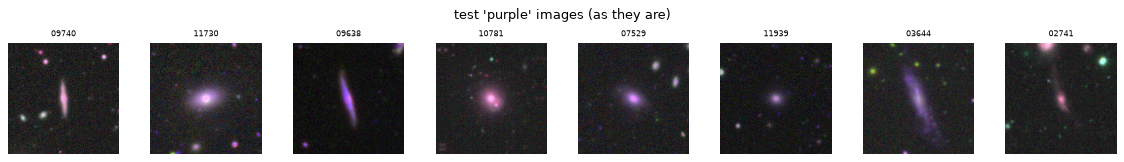

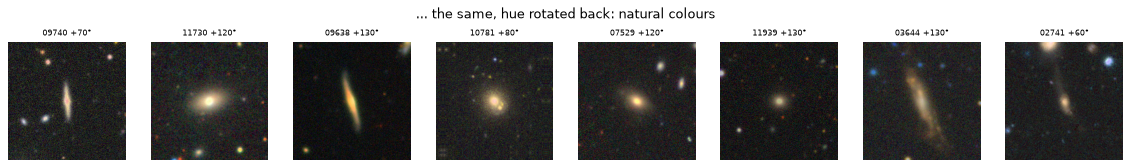

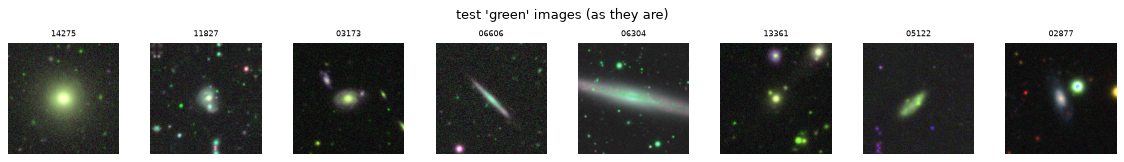

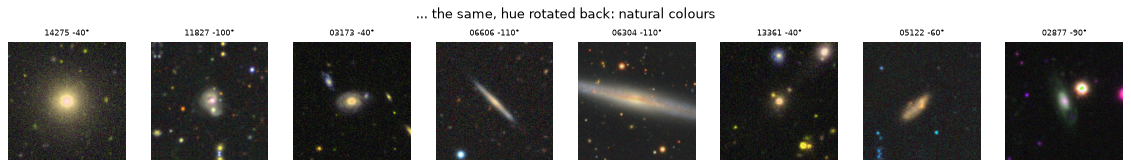

In [6]:
def rotate_hue(img, deg):
    # rotate the hue of a whole PIL image by deg degrees (PIL's HSV uses 0-255 for the hue)
    h, s, v = img.convert("HSV").split()
    h = h.point(lambda x: int(x + round(deg / 360 * 256)) % 256)
    return Image.merge("HSV", (h, s, v)).convert("RGB")

for kind in ["purple", "green"]:
    ex = tinted[(tinted.tint == kind) & rot_ok].sample(8, random_state=1)
    show(ex.id, suptitle=f"test '{kind}' images (as they are)")
    fig, axes = plt.subplots(1, 8, figsize=(14.4, 2.1))
    for ax, r in zip(axes, ex.itertuples()):
        ax.imshow(rotate_hue(C.load_image(r.id), r.undo_angle)); ax.set_title(f"{r.id[5:]} {r.undo_angle:+d}°", fontsize=7); ax.axis("off")
    fig.suptitle(f"... the same, hue rotated back: natural colours"); plt.tight_layout(); plt.show()

### 1d. How many images are rotated
The rule of 1b only catches rotations that push the core colour **outside** the natural band; some rotations keep it inside (e.g. a nearly grey core stays grey). So 22% is a **lower bound** of the rotated images.

A second estimate compares the **hue distribution** of the core in the test and in the clean training set: the test has an **excess** of images at hues that are rare in the training set. The smallest excess compatible with the training distribution is another lower bound.

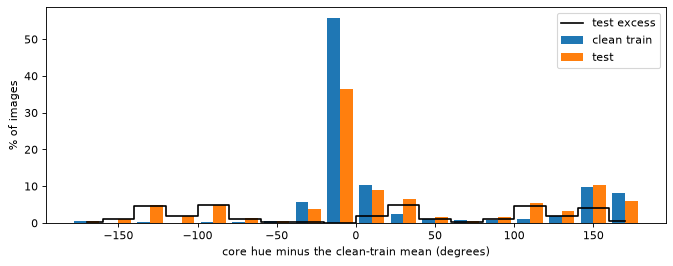

altered share of the test (lower bound from the hue excess): 34.6%


In [7]:
def hue(df):
    return np.array([colorsys.rgb_to_hsv(r / 255, g / 255, b / 255)[0] * 360
                     for r, g, b in zip(df.core_r, df.core_g, df.core_b)])
wrap = lambda a: (a + 180) % 360 - 180
h_tr, h_te = hue(train), hue(test)
h0 = np.rad2deg(np.angle(np.exp(1j * np.deg2rad(h_tr)).mean()))        # mean hue of the clean training set
d_tr, d_te = wrap(h_tr - h0), wrap(h_te - h0)

bins = np.arange(-180, 181, 20)
p_tr = np.histogram(d_tr, bins)[0] / len(d_tr)
p_te = np.histogram(d_te, bins)[0] / len(d_te)
scale = min(p_te[p_tr > 0] / p_tr[p_tr > 0])          # largest share of the test that can be "train-like"
excess = np.clip(p_te - scale * p_tr, 0, None)

fig, ax = plt.subplots(figsize=(10, 3.5))
w = 8
ax.bar(bins[:-1] + 10 - w / 2, 100 * p_tr, width=w, label="clean train")
ax.bar(bins[:-1] + 10 + w / 2, 100 * p_te, width=w, label="test")
ax.step(bins[:-1] + 10, 100 * excess, where="mid", color="k", label="test excess")
ax.set_xlabel("core hue minus the clean-train mean (degrees)"); ax.set_ylabel("% of images"); ax.legend()
plt.show()
print(f"altered share of the test (lower bound from the hue excess): {100 * excess.sum():.1f}%")

**Reading.** The clean training set has two hue modes (yellow ellipticals and blue spirals). The test shows extra images at hues that are rare in the training set: at least **~35%** of the test is altered, consistent with Davide's estimate (≥ 35%).

### 1e. Fitting the rotation: angle and share
We simulate the rotation on the cores of the clean training set and search for the **angle range**, the **share of negative rotations** and the **share P of rotated images** whose mixture `(1 − P) · train + P · rotated train` best reproduces the **full hue histogram** of the test. As a check, we also predict the share of visibly tinted images and the purple / green split, and compare them with the test.

In [8]:
H_tr = np.array([colorsys.rgb_to_hsv(*(c / 255)) for c in train[["core_r", "core_g", "core_b"]].to_numpy()])
H_te = np.array([colorsys.rgb_to_hsv(*(c / 255)) for c in test[["core_r", "core_g", "core_b"]].to_numpy()])
hb = np.arange(0, 361, 15)
hist = lambda H: np.histogram(H[:, 0] * 360, hb)[0] / len(H)
target = hist(H_te)
test_tinted = (test.tint != "").mean()
test_purple = (test.tint == "purple").sum() / (test.tint != "").sum()

rng = np.random.default_rng(0)
rows = []
for a_lo, a_hi in [(60, 140), (90, 150), (100, 140), (110, 130), (60, 180)]:
    for p_neg in [0.5, 0.6]:
        deg = rng.uniform(a_lo, a_hi, len(H_tr)) * np.where(rng.random(len(H_tr)) < p_neg, -1, 1)
        H_rot = H_tr.copy(); H_rot[:, 0] = (H_rot[:, 0] + deg / 360) % 1
        rgb_rot = np.array([colorsys.hsv_to_rgb(*x) for x in H_rot])
        cg_rot = rgb_rot[:, 1] / rgb_rot.sum(1)
        flagged = (cg_rot < lo) | (cg_rot > hi)
        for P in [0.20, 0.25, 0.30, 0.35, 0.40]:
            mix = (1 - P) * hist(H_tr) + P * hist(H_rot)
            rows.append({"angle range": (a_lo, a_hi), "share negative": p_neg, "P rotated": P,
                         "L1 distance": np.abs(mix - target).sum(),
                         "predicted tinted %": 100 * (P * flagged.mean() + (1 - P) * 0.02),
                         "predicted purple share": (cg_rot < lo).sum() / max(flagged.sum(), 1)})
fit_col = pd.DataFrame(rows).sort_values("L1 distance")
print(f"test: tinted {100 * test_tinted:.1f}%, purple share {test_purple:.2f}")
fit_col.head(8).round(3)

test: tinted 21.8%, purple share 0.58


,angle range,share negative,P rotated,L1 distance,predicted tinted %,predicted purple share
22,"(100, 140)",0.5,0.30,0.219,22.826,0.610
31,"(110, 130)",0.5,0.25,0.223,19.438,0.597
36,"(110, 130)",0.6,0.25,0.225,19.931,0.675
30,"(110, 130)",0.5,0.20,0.226,15.951,0.597
27,"(100, 140)",0.6,0.30,0.229,23.307,0.663
23,"(100, 140)",0.5,0.35,0.234,26.297,0.610
32,"(110, 130)",0.5,0.30,0.235,22.926,0.597
26,"(100, 140)",0.6,0.25,0.235,19.755,0.663


**Reading.** The top configurations are **equivalent**: their L1 distances differ by less than the random variation of the fit (the order of the first rows can change from one run to another). They all say the same thing:
- the rotation is about **±120°** (range 110–130° or 100–140°), half in each direction;
- the rotated share is between **25% and 30%**.

To choose within this range we use the independent check, the share of **visibly tinted** images: P = 0.25 predicts ≈ 19.5%, P = 0.30 predicts ≈ 23%, and the test has ≈ 21.8%. We therefore take:
- **angle ±(100–140)°**: the wider range, which also contains 110–130° and makes us less dependent on the precision of the estimate;
- **P = 0.28**: the share that reproduces the visibly tinted images of the test.

*Note:* a rotation of exactly ±120° is the same as **cyclically shifting the RGB channels** (R→G→B→R), which explains why channel permutations looked like a plausible first guess.

Simulation on whole images (clean training images, rotated by ±U(100, 140)°):

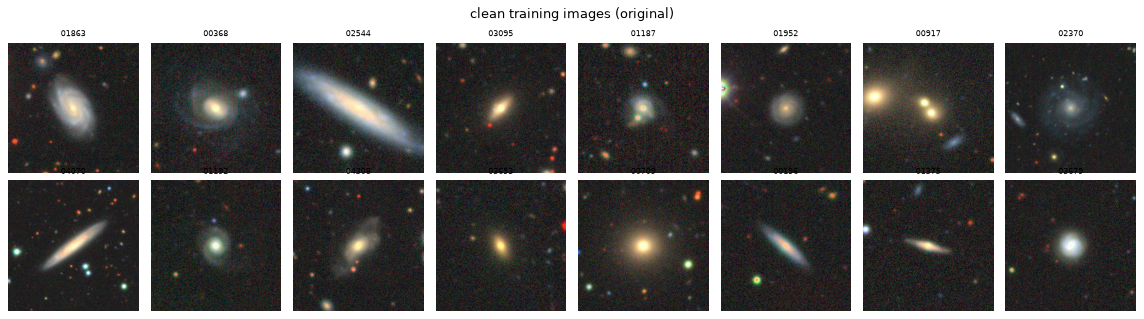

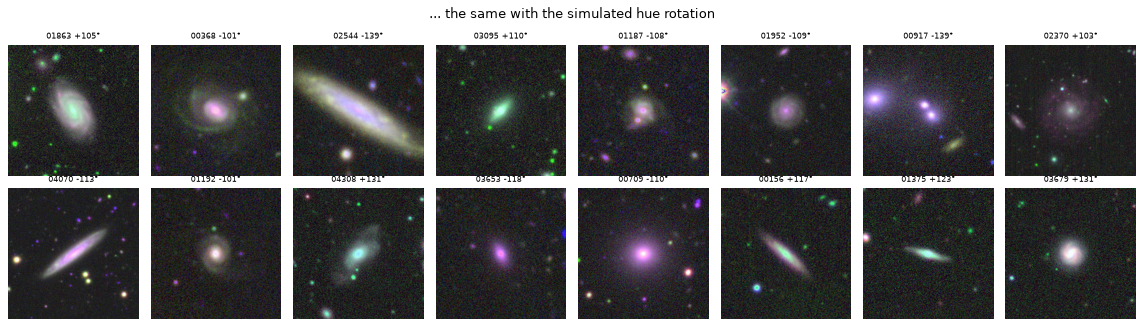

In [9]:
sample_ids = train.sample(16, random_state=0).id.tolist()
degs = rng.uniform(100, 140, 16) * rng.choice([-1, 1], 16)
show(sample_ids, suptitle="clean training images (original)")
fig, axes = plt.subplots(2, 8, figsize=(14.4, 4.2))
for ax, i, d in zip(axes.ravel(), sample_ids, degs):
    ax.imshow(rotate_hue(C.load_image(i), d)); ax.set_title(f"{i[6:]} {d:+.0f}°", fontsize=7); ax.axis("off")
fig.suptitle("... the same with the simulated hue rotation"); plt.tight_layout(); plt.show()

## 2. Blur

### 2a. Measuring sharpness
We measure the **share of fine detail** in the centre of the image: with the Fourier transform of the central 128×128 square we compute the ratio between high-frequency energy (details, edges) and low-frequency energy (broad shapes). The blurrier the image, the lower the ratio. Unlike pixel noise, this measures the sharpness of the **galaxy**.

We compare the full distribution on a random sample of the clean training set and of the test.

In [10]:
def detail_ratio(img):
    g = np.asarray(img.convert("L"), np.float32)[64:192, 64:192]
    F = np.abs(np.fft.fftshift(np.fft.fft2(g - g.mean()))) ** 2
    y, x = np.indices(F.shape)
    r = np.hypot(y - 64, x - 64)
    return F[(r > 16) & (r < 40)].sum() / F[(r > 2) & (r <= 16)].sum()

tr_ids = train.sample(400, random_state=0).id.tolist()
te_ids = test.sample(1500, random_state=0).id.tolist()
d_train = np.array([detail_ratio(C.load_image(i)) for i in tqdm(tr_ids)])
d_test = np.array([detail_ratio(C.load_image(i)) for i in tqdm(te_ids)])

q = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90]
pd.DataFrame({"clean train": np.quantile(d_train, q), "test": np.quantile(d_test, q)},
             index=[f"{int(100*x)}th pct" for x in q]).round(3)

  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

,clean train,test
5th pct,0.054,0.027
10th pct,0.066,0.041
25th pct,0.091,0.071
50th pct,0.133,0.119
75th pct,0.195,0.195
90th pct,0.327,0.310


**Reading.** The **upper half** of the two distributions is the same: most test images are as sharp as the training images. Only the **lower tail** of the test is softer: a subset of blurred images, not a general smoothing of the whole test.

### 2b. Fitting the blur
We simulate on the clean training sample: an optional **light blur on every image** (sigma_all) plus a **stronger blur on a share p** of the images (sigma drawn in a range), and look for the combination whose sharpness distribution best matches the test (mean distance between the log-quantiles).

In [11]:
qq = np.linspace(0.05, 0.95, 10)
target = np.log(np.quantile(d_test, qq))
imgs = [C.load_image(i) for i in tr_ids]

def simulate(sigma_all, p, rng_sigma, seed=0):
    rng = np.random.default_rng(seed)
    out = []
    for img in imgs:
        s = sigma_all
        if rng.random() < p:
            s = max(s, rng.uniform(*rng_sigma))
        out.append(detail_ratio(C.apply_shift(img, blur_sigma=s) if s > 0 else img))
    return np.array(out)

rows = []
for sigma_all in [0, 0.3]:
    for p in [0.15, 0.20, 0.25]:
        for rng_sigma in [(0.5, 0.9), (0.6, 1.0), (0.7, 1.2)]:
            v = simulate(sigma_all, p, rng_sigma)
            rows.append({"sigma_all": sigma_all, "p": p, "sigma range": rng_sigma,
                         "distance": np.abs(np.log(np.quantile(v, qq)) - target).mean()})
fit = pd.DataFrame(rows).sort_values("distance")
fit.head(6).round(4)

,sigma_all,p,sigma range,distance
4,0.0,0.20,"(0.6, 1.0)",0.0622
2,0.0,0.15,"(0.7, 1.2)",0.0657
6,0.0,0.25,"(0.5, 0.9)",0.0763
1,0.0,0.15,"(0.6, 1.0)",0.0773
3,0.0,0.20,"(0.5, 0.9)",0.0774
10,0.3,0.15,"(0.6, 1.0)",0.0804


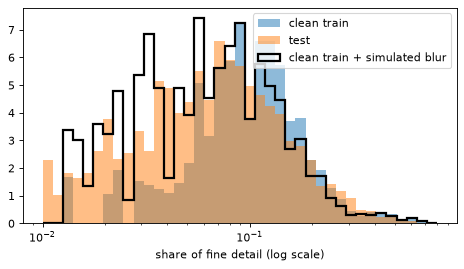

best fit: sigma_all=0.0, p=0.2, sigma range=(0.6, 1.0)


In [12]:
best = fit.iloc[0]
v_best = simulate(best.sigma_all, best.p, best["sigma range"])
fig, ax = plt.subplots(figsize=(7, 3.5))
bins_d = np.logspace(np.log10(0.01), np.log10(0.8), 40)
ax.hist(d_train, bins_d, density=True, alpha=.5, label="clean train")
ax.hist(d_test, bins_d, density=True, alpha=.5, label="test")
ax.hist(v_best, bins_d, density=True, histtype="step", lw=2, color="k", label="clean train + simulated blur")
ax.set_xscale("log"); ax.set_xlabel("share of fine detail (log scale)"); ax.legend(); plt.show()
print(f"best fit: sigma_all={best.sigma_all}, p={best.p}, sigma range={best['sigma range']}")

**Reading.** The best fit has **no general smoothing** (sigma_all = 0) and about **20%** of blurred images with sigma around **0.6–1.0**: a mild blur. The simulated distribution (black line) follows the test closely.

*Cross-check:* Davide flags 2,502 test images (17.0%) as `smooth`, based on a different measure (sky grain). The two lists overlap on the clear cases; the borderline cases differ because softness is a continuum.

## 3. Other differences

### 3a. Sky grain and sky brightness
We compare the background noise (`noise`, from `00_eda`) and the brightness of the sky (median of the 30% darkest pixels) between the clean training set and the test.

In [13]:
def sky_level(img_id):
    a = np.asarray(C.load_image(img_id).convert("L"), np.float32).ravel()
    return np.median(a[a <= np.quantile(a, 0.3)])

sky_tr = np.array([sky_level(i) for i in tr_ids])
sky_te = np.array([sky_level(i) for i in te_ids])
q = [0.10, 0.50, 0.90, 0.97]
pd.DataFrame({
    "noise, clean train": np.quantile(train.noise, q), "noise, test": np.quantile(test.noise, q),
    "sky, clean train": np.quantile(sky_tr, q), "sky, test": np.quantile(sky_te, q),
}, index=[f"{int(100*x)}th pct" for x in q]).round(1)

,"noise, clean train","noise, test","sky, clean train","sky, test"
10th pct,3.0,2.0,21.0,16.9
50th pct,5.0,4.0,24.0,24.0
90th pct,6.0,6.0,27.0,30.0
97th pct,7.0,8.0,30.0,38.0


**Reading.**
- The test sky is overall **slightly less grainy** than the training sky. It is a mild, general difference: we leave it to the **training augmentation** (random noise / slight smoothing), not to the shifted validation.
- A small share of the test (~3%, Davide's `grainy_like`) has a **brighter, grainier sky**. These are real images, much milder than the brightened copies removed from the training set. Too few to simulate: covered by brightness/noise augmentation.

### 3b. Blank images and alien candidates
Davide's audit flags **2 blank** test images (no galaxy: impossible to classify, any prediction is a guess) and **4 alien candidates** (checked by eye: no aliens; the EDA also found none). Both are negligible (≤ 0.04% of the test) and are **not** simulated.

## 4. Proposal for the shifted validation

| alteration | share of validation images | how | evidence |
|---|---|---|---|
| **colour** | **28%** | **hue rotation** by ±(100–140)°, half in each direction | 99.7% of tinted cores are restored by a hue rotation; the fit of the full hue histogram gives ±120° on 25–30% of the images; 28% reproduces the 21.8% of visibly tinted test images; predicted purple share ≈ 0.6 (test 0.58) |
| **blur** | **20%** | Gaussian blur, **sigma 0.6–1.0** | best fit of the full sharpness distribution |
| other (sky grain, brighter sky, blank, aliens) | – | not simulated | mild or negligible; covered by training augmentation |

The two alterations are drawn independently, so some images get both and about 58% stay untouched.

**Consequences for training:**
- a **large hue rotation** on part of the images is the most targeted augmentation against the colour shift (e.g. `ColorJitter(hue=0.5)`, or a cyclic shift of the RGB channels, which equals a ±120° rotation);
- a mild **Gaussian blur** (sigma up to ~1) on part of the images covers the blur;
- brightness and noise augmentations cover the remaining minor differences.

These parameters are a **proposal to be agreed by the team**; once agreed, they are written in `common.py` and used by `03_validation_setup`.